=== Circuit Diagram (Willow Grid Layout) ===
(0, 0): ───H───iSwap───────Rz(0.25π)───M('result')───
               │                       │
(0, 1): ───────iSwap^0.5───────────────M─────────────


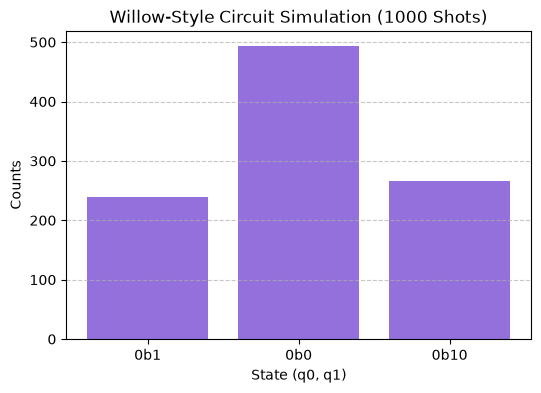

In [3]:
import cirq
import matplotlib.pyplot as plt

# 1. Define Qubits using a 2D Grid layout
q0 = cirq.GridQubit(0, 0)
q1 = cirq.GridQubit(0, 1)

# 2. Build a circuit using native Cirq gates
circuit = cirq.Circuit(
    cirq.H(q0),                             # Prepare superposition on q0
    cirq.SQRT_ISWAP(q0, q1),                 # Native Google entangling gate
    cirq.rz(rads=0.25 * 3.14159).on(q0),     # Phase rotation (lowercase 'rz')
    cirq.measure(q0, q1, key='result')       # Simultaneous readout
)

# 3. Text-based Visual Rendering in VS Code Output
print("=== Circuit Diagram (Willow Grid Layout) ===")
print(circuit)

# 4. Local Execution via Cirq Simulator
simulator = cirq.Simulator()
simulation_result = simulator.run(circuit, repetitions=1000)

# 5. Graphical Visualization of Results using Matplotlib
histogram = simulation_result.histogram(key='result')

plt.figure(figsize=(6, 4))
plt.bar([bin(k) for k in histogram.keys()], histogram.values(), color='mediumpurple')
plt.xlabel('State (q0, q1)')
plt.ylabel('Counts')
plt.title('Willow-Style Circuit Simulation (1000 Shots)')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

Target Search State: |101010101⟩ out of 512 total states.
Applying 17 Grover iterations...

Running Cirq Simulator...
Done in 0.029 seconds.

Target state |101010101⟩ found 1000 / 1000 times (100.0% probability).


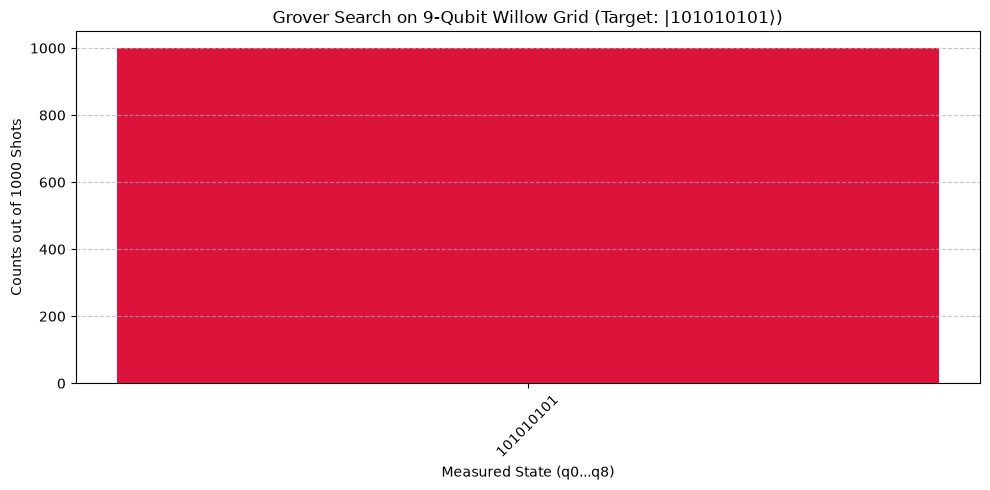

In [4]:
import time
import cirq
import matplotlib.pyplot as plt
import numpy as np

# 1. Setup Willow 2D Grid Qubits (3x3 Grid = 9 Qubits)
grid_size = 3
qubits = [cirq.GridQubit(r, c) for r in range(grid_size) for c in range(grid_size)]
num_qubits = len(qubits)
N = 2 ** num_qubits

target_bitstring = "101010101"
print(f"Target Search State: |{target_bitstring}⟩ out of {N} total states.")

# 2. Build Grover Components
def make_oracle(qubits, target):
    for i, bit in enumerate(target):
        if bit == '0':
            yield cirq.X(qubits[i])
    yield cirq.Z(qubits[-1]).controlled_by(*qubits[:-1])
    for i, bit in enumerate(target):
        if bit == '0':
            yield cirq.X(qubits[i])

def make_diffuser(qubits):
    yield [cirq.H(q) for q in qubits]
    yield [cirq.X(q) for q in qubits]
    yield cirq.Z(qubits[-1]).controlled_by(*qubits[:-1])
    yield [cirq.X(q) for q in qubits]
    yield [cirq.H(q) for q in qubits]

# 3. Assemble Circuit
circuit = cirq.Circuit()
circuit.append([cirq.H(q) for q in qubits])

num_iterations = int(np.pi / 4 * np.sqrt(N))
print(f"Applying {num_iterations} Grover iterations...")

for _ in range(num_iterations):
    circuit.append(make_oracle(qubits, target_bitstring))
    circuit.append(make_diffuser(qubits))

circuit.append(cirq.measure(*qubits, key='result'))

# 4. Simulate using standard Cirq Simulator
print("\nRunning Cirq Simulator...")
start_time = time.time()

simulator = cirq.Simulator()
result = simulator.run(circuit, repetitions=1000)

execution_time = time.time() - start_time
print(f"Done in {execution_time:.3f} seconds.")

# 5. Plot Results
counts = result.histogram(key='result')
top_states = sorted(counts.items(), key=lambda x: x[1], reverse=True)[:10]

bitstrings = [bin(k)[2:].zfill(num_qubits) for k, v in top_states]
frequencies = [v for k, v in top_states]

target_int = int(target_bitstring, 2)
target_count = counts.get(target_int, 0)
print(f"\nTarget state |{target_bitstring}⟩ found {target_count} / 1000 times ({(target_count/10):.1f}% probability).")

plt.figure(figsize=(10, 5))
colors = ['crimson' if b == target_bitstring else 'teal' for b in bitstrings]
plt.bar(range(len(bitstrings)), frequencies, color=colors)
plt.xticks(range(len(bitstrings)), bitstrings, rotation=45)
plt.xlabel('Measured State (q0...q8)')
plt.ylabel('Counts out of 1000 Shots')
plt.title(f'Grover Search on 9-Qubit Willow Grid (Target: |{target_bitstring}⟩)')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

=== Surface Code Error Syndrome Detection ===
X-Syndrome (Phase Flip Flag): Counter({1: 503, 0: 497})
Z-Syndrome (Bit Flip Flag):   Counter({0: 511, 1: 489})


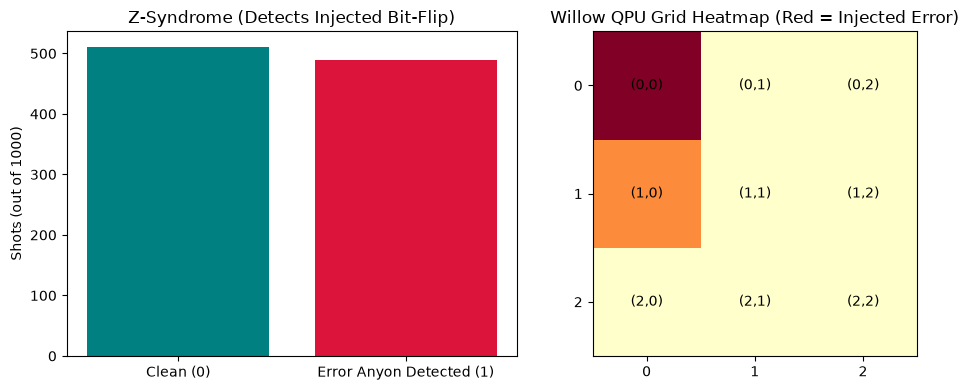

In [6]:
import time
import cirq
import matplotlib.pyplot as plt
import numpy as np

# 1. Map a 3x3 Surface Code Patch on Willow's 2D Grid
# Unpack r (row) and c (col) properly from coordinate tuples
data_qubits = [cirq.GridQubit(r, c) for r, c in [(0,0), (0,2), (1,1), (2,0), (2,2)]]
ancilla_x = cirq.GridQubit(0, 1) # Detects Z-phase errors across adjacent data qubits
ancilla_z = cirq.GridQubit(1, 0) # Detects X-bitflip errors across adjacent data qubits

all_qubits = data_qubits + [ancilla_x, ancilla_z]

circuit = cirq.Circuit()

# 2. Entangle Data Qubits into a Surface Code Stabilizer State
circuit.append([
    cirq.H(data_qubits[0]),
    cirq.CNOT(data_qubits[0], data_qubits[1]),
    cirq.CNOT(data_qubits[1], data_qubits[2]),
    cirq.CNOT(data_qubits[2], data_qubits[3]),
    cirq.CNOT(data_qubits[3], data_qubits[4]),
])

# 3. Inject intentional bit-flip error on Data Qubit (0,0)
error_qubit = data_qubits[0]
circuit.append(cirq.X(error_qubit)) 

# 4. Syndrome Extraction Circuits
# --- Measure X-Stabilizer ---
circuit.append(cirq.H(ancilla_x))
circuit.append(cirq.CNOT(ancilla_x, data_qubits[0]))
circuit.append(cirq.CNOT(ancilla_x, data_qubits[1]))
circuit.append(cirq.H(ancilla_x))

# --- Measure Z-Stabilizer ---
circuit.append(cirq.CNOT(data_qubits[0], ancilla_z))
circuit.append(cirq.CNOT(data_qubits[3], ancilla_z))

# 5. Readout Measurement
circuit.append(cirq.measure(ancilla_x, key='Syndrome_X'))
circuit.append(cirq.measure(ancilla_z, key='Syndrome_Z'))
circuit.append(cirq.measure(*data_qubits, key='Data_Readout'))

# 6. Simulate Execution
simulator = cirq.Simulator()
result = simulator.run(circuit, repetitions=1000)

# Extract Syndrome Detection Rates
syn_x_counts = result.histogram(key='Syndrome_X')
syn_z_counts = result.histogram(key='Syndrome_Z')

print("=== Surface Code Error Syndrome Detection ===")
print(f"X-Syndrome (Phase Flip Flag): {syn_x_counts}")
print(f"Z-Syndrome (Bit Flip Flag):   {syn_z_counts}")

# 7. Visualizing Error Anyon Detection
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 4))

ax1.bar(['Clean (0)', 'Error Anyon Detected (1)'], 
        [syn_z_counts.get(0, 0), syn_z_counts.get(1, 0)], color=['teal', 'crimson'])
ax1.set_title('Z-Syndrome (Detects Injected Bit-Flip)')
ax1.set_ylabel('Shots (out of 1000)')

grid_matrix = np.zeros((3, 3))
grid_matrix[0, 0] = 1 # Error location
grid_matrix[1, 0] = 0.5 # Ancilla syndrome trigger

ax2.imshow(grid_matrix, cmap='YlOrRd', vmin=0, vmax=1)
ax2.set_xticks([0, 1, 2])
ax2.set_yticks([0, 1, 2])
ax2.set_title('Willow QPU Grid Heatmap (Red = Injected Error)')
for r in range(3):
    for c in range(3):
        ax2.text(c, r, f"({r},{c})", ha='center', va='center', color='black')

plt.tight_layout()
plt.show()

In [7]:
import cirq
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# -------------------------------------------------------------------
# 1. System Setup: 10 Qubits mapped on a 2D Grid Line
# -------------------------------------------------------------------
num_qubits = 10
qubits = [cirq.GridQubit(0, i) for i in range(num_qubits)]

def build_time_step_circuit(qubits, dt, Jx=1.0, Jy=0.5, Jz=0.2):
    """
    Constructs a single Trotterized time-evolution step (e^(-i H dt))
    for a 1D Nearest-Neighbor Spin Chain.
    """
    circuit = cirq.Circuit()
    
    # XX interaction using native Cirq gates
    for i in range(0, num_qubits - 1, 2):
        circuit.append(cirq.XXPowGate(exponent=2 * Jx * dt / np.pi)(qubits[i], qubits[i+1]))
    for i in range(1, num_qubits - 1, 2):
        circuit.append(cirq.XXPowGate(exponent=2 * Jx * dt / np.pi)(qubits[i], qubits[i+1]))

    # YY interaction
    for i in range(0, num_qubits - 1, 2):
        circuit.append(cirq.YYPowGate(exponent=2 * Jy * dt / np.pi)(qubits[i], qubits[i+1]))
    for i in range(1, num_qubits - 1, 2):
        circuit.append(cirq.YYPowGate(exponent=2 * Jy * dt / np.pi)(qubits[i], qubits[i+1]))

    # ZZ interaction
    for i in range(0, num_qubits - 1, 2):
        circuit.append(cirq.ZZPowGate(exponent=2 * Jz * dt / np.pi)(qubits[i], qubits[i+1]))
    for i in range(1, num_qubits - 1, 2):
        circuit.append(cirq.ZZPowGate(exponent=2 * Jz * dt / np.pi)(qubits[i], qubits[i+1]))

    return circuit

# -------------------------------------------------------------------
# 2. Execute Time Evolution Simulation
# -------------------------------------------------------------------
time_steps = 40
dt = 0.15
simulator = cirq.Simulator()

# Initial State: Localized spin excitation at the center qubit
initial_circuit = cirq.Circuit(cirq.X(qubits[0])) # Excitation starting at qubit 0

space_time_data = np.zeros((time_steps, num_qubits))
final_state_vector = None

# Step through continuous time
running_circuit = initial_circuit.copy()
step_circuit = build_time_step_circuit(qubits, dt)

for t in range(time_steps):
    result = simulator.simulate(running_circuit)
    state_vector = result.final_state_vector
    
    # Calculate expectation value <Z> -> Probability of |1> on each qubit
    for q_idx in range(num_qubits):
        prob_1 = np.sum(np.abs(state_vector[np.arange(2**num_qubits) & (1 << (num_qubits - 1 - q_idx)) != 0]) ** 2)
        space_time_data[t, q_idx] = prob_1
        
    running_circuit += step_circuit
    if t == time_steps - 1:
        final_state_vector = state_vector

# -------------------------------------------------------------------
# 3. Comprehensive Multi-Panel Visualization
# -------------------------------------------------------------------
fig = plt.figure(figsize=(14, 10))
gs = fig.add_gridspec(2, 2, height_ratios=[1.2, 1])

# Panel A: Space-Time Heatmap (Information Propagation)
ax1 = fig.add_subplot(gs[0, :])
sns.heatmap(space_time_data.T, ax=ax1, cmap='magma', cbar_kws={'label': 'Excitation Probability P(|1⟩)'})
ax1.set_title('Quantum Information Dispersion (Quantum Light-Cone Dynamics)', fontsize=14, pad=10)
ax1.set_xlabel('Time Step (t)', fontsize=11)
ax1.set_ylabel('Qubit Index (Grid Spatial Position)', fontsize=11)
ax1.invert_yaxis()

# Panel B: Select Qubit Trajectories
ax2 = fig.add_subplot(gs[1, 0])
times = np.arange(time_steps) * dt
ax2.plot(times, space_time_data[:, 0], label='Qubit 0 (Initial Source)', color='crimson', lw=2)
ax2.plot(times, space_time_data[:, 3], label='Qubit 3 (Mid Chain)', color='teal', lw=2)
ax2.plot(times, space_time_data[:, 9], label='Qubit 9 (Edge Chain)', color='goldenrod', lw=2)
ax2.set_title('Local Qubit Excitation Profiles Over Time', fontsize=12)
ax2.set_xlabel('Simulated Time (t)', fontsize=11)
ax2.set_ylabel('P(|1⟩)', fontsize=11)
ax2.grid(True, linestyle='--', alpha=0.5)
ax2.legend(loc='upper right')

# Panel C: Final Statevector Density Matrix (Amplitudes)
ax3 = fig.add_subplot(gs[1, 1])
amplitude_matrix = np.abs(np.outer(final_state_vector, np.conj(final_state_vector)))[:32, :32]
cax = ax3.imshow(amplitude_matrix, cmap='viridis', interpolation='nearest')
fig.colorbar(cax, ax=ax3, label='Density Matrix Magnitude')
ax3.set_title('Truncated Density Matrix Magnitude at t_final (Sub-basis 2^5)', fontsize=12)
ax3.set_xlabel('Computational Basis State', fontsize=11)
ax3.set_ylabel('Computational Basis State', fontsize=11)

plt.tight_layout()
plt.show()

ModuleNotFoundError: No module named 'seaborn'